In [1]:
import numpy as np
import pandas as pd
import os
import string
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk import PorterStemmer as Stemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

Chargement des données

['spam.csv', 'Spam.ipynb']
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
      message                                                               
        count unique                                                top freq
label                                                                       
ham      4825   4516                             Sorry, I'll call later   30
spam      747    653  Please call our customer service representativ...    4


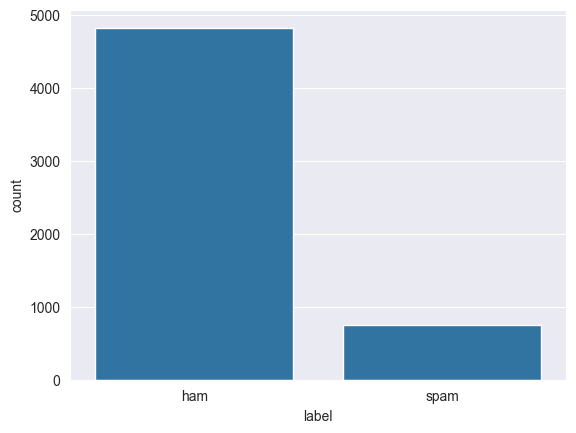

In [2]:
print(os.listdir("C:/Users/USER/PycharmProjects/TP2/BNaif"))
df = pd.read_csv('C:/Users/USER/PycharmProjects/TP2/BNaif/spam.csv', encoding='latin-1')[['v1', 'v2']]
df.columns = ['label', 'message']
print(df.head())
print(df.groupby('label').describe())
sns.countplot(data=df, x='label')
plt.show()


Prétraitement du texte

In [3]:
stop = set(stopwords.words('english'))
st = Stemmer()

def process(text):
    text = text.lower()                                              # minuscules
    text = ''.join([t for t in text if t not in string.punctuation]) # ponctuation
    text = [t for t in text.split() if t not in stop]                # mots vides
    text = [st.stem(t) for t in text]                                # stemming
    return text

# Tests
print(process("It's holiday and we are playing cricket. Jeff is playing very well!!!"))
print(df['message'][:20].apply(process))

['holiday', 'play', 'cricket', 'jeff', 'play', 'well']
0     [go, jurong, point, crazi, avail, bugi, n, gre...
1                          [ok, lar, joke, wif, u, oni]
2     [free, entri, 2, wkli, comp, win, fa, cup, fin...
3         [u, dun, say, earli, hor, u, c, alreadi, say]
4     [nah, dont, think, goe, usf, live, around, tho...
5     [freemsg, hey, darl, 3, week, word, back, id, ...
6     [even, brother, like, speak, treat, like, aid,...
7     [per, request, mell, mell, oru, minnaminungint...
8     [winner, valu, network, custom, select, receiv...
9     [mobil, 11, month, u, r, entitl, updat, latest...
10    [im, gonna, home, soon, dont, want, talk, stuf...
11    [six, chanc, win, cash, 100, 20000, pound, txt...
12    [urgent, 1, week, free, membership, å£100000, ...
13    [ive, search, right, word, thank, breather, pr...
14                                       [date, sunday]
15    [xxxmobilemovieclub, use, credit, click, wap, ...
16                                     [oh, kim, 

TF-IDF : visualisation d'un message

In [4]:
tfidfv = TfidfVectorizer(analyzer=process)
data = tfidfv.fit_transform(df['message'])
mess = df.iloc[2]['message']
print(mess)
print(tfidfv.transform([mess]))

j = tfidfv.transform([mess]).toarray()[0]
print('index\tidf\ttfidf\tterm')
for i in range(len(j)):
    if j[i] != 0:
        print(i, format(tfidfv.idf_[i], '.4f'), format(j[i], '.4f'),
              tfidfv.get_feature_names_out()[i], sep='\t')

Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 21 stored elements and shape (1, 8097)>
  Coords	Values
  (0, 72)	0.2330497030932461
  (0, 413)	0.09987750376879972
  (0, 420)	0.22518719340674634
  (0, 433)	0.22518719340674634
  (0, 833)	0.2190885570936267
  (0, 1180)	0.16669800498830506
  (0, 2076)	0.19516151371199045
  (0, 2246)	0.20302402339849024
  (0, 2748)	0.3571909758763146
  (0, 2868)	0.4660994061864922
  (0, 2969)	0.16669800498830506
  (0, 3091)	0.11505037200973967
  (0, 4592)	0.15903719770411495
  (0, 5768)	0.2330497030932461
  (0, 5815)	0.2330497030932461
  (0, 5856)	0.16027970945850903
  (0, 6959)	0.11759458460817876
  (0, 7099)	0.2190885570936267
  (0, 7276)	0.12336193745345178
  (0, 7708)	0.14471405235314777
  (0, 7741)	0.18906287739887084
index	idf	tfidf	term
72	8.5271	0.2330	08452810075over18
413	3.6544	

La valeur dans chaque case est le score TF-IDF :

TF (term frequency) : combien de fois le mot apparaît dans ce message.
IDF (inverse document frequency) : un poids qui est faible pour un mot présent dans presque tous les messages, et élevé pour un mot rare. Plus le mot est rare, plus il est informatif.
TF × IDF, puis le vecteur est normalisé (longueur 1).

fit_transform fait deux choses : il construit le vocabulaire et calcule les IDF (le fit), puis il transforme les textes en une matrice creuse (le transform). Cette matrice a une ligne par message et une colonne par mot.

In [5]:
# ------------------------------------------------------------------
# Apprentissage
# ------------------------------------------------------------------
spam_filter = Pipeline([
    ('vectorizer', TfidfVectorizer(analyzer=process)),  # messages -> scores TF-IDF
    ('classifier', MultinomialNB())                     # Naive Bayes multinomial
])
x_train, x_test, y_train, y_test = train_test_split(
    df['message'], df['label'], test_size=0.20, random_state=21)

# CORRECTION 2 : un seul fit (il était appelé deux fois)
spam_filter.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


Comment MultinomialNB apprend : il applique le théorème de Bayes. Il calcule, pour chaque classe, la probabilité a priori P(classe) et, pour chaque mot, P(mot | classe) à partir des scores du train. À la prédiction, il choisit la classe qui maximise P(classe) × ∏ P(mot | classe). Le produit vient de l’hypothèse d’indépendance des mots (c’est la Q2c).

Total number of test cases 1115
Number of wrong of predictions 39
                                                message  vrai prédit
419   Send a logo 2 ur lover - 2 names joined by a h...  spam    ham
3139  sexy sexy cum and text me im wet and warm and ...  spam    ham
3790  Twinks, bears, scallies, skins and jocks are c...  spam    ham
2877  Hey Boys. Want hot XXX pics sent direct 2 ur p...  spam    ham
2377  YES! The only place in town to meet exciting a...  spam    ham
1499  SMS. ac JSco: Energy is high, but u may not kn...  spam    ham
3417  LIFE has never been this much fun and great un...  spam    ham
3358  Sorry I missed your call let's talk when you h...  spam    ham
2412  I don't know u and u don't know me. Send CHAT ...  spam    ham
3862  Oh my god! I've found your number again! I'm s...  spam    ham
659   88800 and 89034 are premium phone services cal...  spam    ham
3109  Good Luck! Draw takes place 28th Feb 06. Good ...  spam    ham
5466  http//tms. widelive.com/index. 

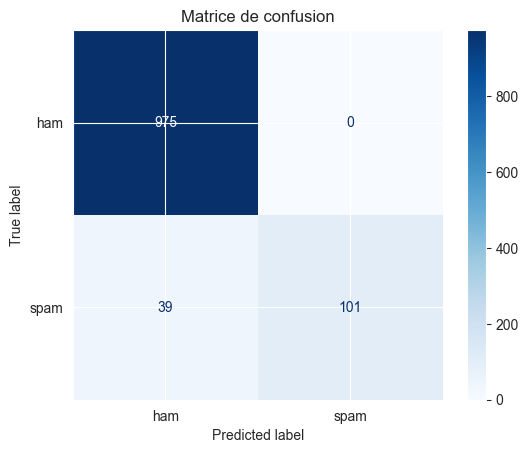

In [6]:
# ------------------------------------------------------------------
# Test
# ------------------------------------------------------------------
predictions = spam_filter.predict(x_test)
mask = (y_test.values != predictions)
print('Total number of test cases', len(y_test))
print('Number of wrong of predictions', mask.sum())

# Q2a : visualisation des prédictions erronées
err = x_test[mask].to_frame()
err['vrai'] = y_test[mask]
err['prédit'] = predictions[mask]
print(err)

cm = confusion_matrix(y_test, predictions, labels=['ham', 'spam'])
ConfusionMatrixDisplay(cm, display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.title("Matrice de confusion")
plt.show()

In [9]:
# CORRECTION 3 : ordre des arguments = (y_true, y_pred)
# (avant : (predictions, y_test) -> précision et rappel étaient inversés)
print(classification_report(predictions, y_test))



              precision    recall  f1-score   support

         ham       1.00      0.96      0.98      1014
        spam       0.72      1.00      0.84       101

    accuracy                           0.97      1115
   macro avg       0.86      0.98      0.91      1115
weighted avg       0.97      0.97      0.97      1115



In [8]:
# ------------------------------------------------------------------
# Q2b : prédiction d'un message
# ------------------------------------------------------------------
def detect_spam(s):
    return spam_filter.predict([s])[0]

msg = ('Your cash-balance is currently 500 pounds - to maximize your cash-in now, '
       'send COLLECT to 83600.')
print(detect_spam(msg))
print(spam_filter.classes_, spam_filter.predict_proba([msg]))

spam
['ham' 'spam'] [[0.09206795 0.90793205]]


Pourquoi elle est fausse : Naïve Bayes suppose que, sachant la classe, les mots sont indépendants : P(w₁…wₙ | c) = ∏ P(wᵢ | c). Or dans un texte, les mots sont corrélés. Par exemple, « cash » apparaît souvent avec « prize », « free » avec « call », et la grammaire et le sujet lient les mots entre eux. De plus, le sac de mots ignore l’ordre.

Pourquoi ça marche quand même :

Pour classer, il suffit que l’argmax soit correct, pas que les probabilités soient bien calibrées. Les corrélations gonflent ou dégonflent les probabilités, mais le plus souvent elles ne changent pas laquelle des deux classes gagne.
Chaque mot donne un indice dans le même sens (par exemple « free », « win » et « claim » pointent tous vers spam). Les corrélations amplifient surtout ces indices sans les inverser.
Le modèle a très peu de paramètres. Il est donc peu sujet au surapprentissage, même avec un vocabulaire énorme et peu de données, ce qui compense son biais.
Les probabilités affichées sont souvent trop extrêmes (proches de 0 ou 1), mais la décision reste bonne.


Précision : parmi les messages que le modèle appelle spam, combien le sont vraiment. Une précision basse signifie des faux positifs, donc de vrais messages (code de vérification, facture, convocation) envoyés à la corbeille sans que l’utilisateur le sache.
Rappel : parmi les vrais spams, combien le modèle en attrape. Un rappel bas signifie des faux négatifs, donc des spams qui arrivent dans la boîte de réception.